In [7]:
import librosa
from glob import glob
import os
from tqdm import tqdm

#Ερωτημα 2
def parse_free_digits(directory):
    files = glob(os.path.join(directory, "*.wav"))
    files = [f.replace("\\", "/") for f in files]


    fnames = [f.split("/")[-1].rsplit(".", 1)[0] for f in files]


    digits = [
        "".join(c for c in f if c.isalpha())
        for f in fnames
    ]

  
    speakers = [
        int("".join(c for c in f if c.isdigit()))
        for f in fnames
    ]

    def read_wav(f):
        wav, sr = librosa.load(f, sr=16000)
        #sr = Sampling Rate = Συχνότητα Δειγματοληψίας = Πόσα δείγματα παίρνουμε ανα δευτερόλεπτο (sr = 16000)
        #wav = Voice message waveform = Κυματομορφ΄ή ηχητικού μηνύματος
        return wav, sr

    recordings = [read_wav(f) for f in files]
    wavs = [r[0] for r in recordings]
    sample_rates = [r[1] for r in recordings]

    return digits, speakers, wavs
    

In [8]:
digits,speakers,wavs = parse_free_digits("digits")

In [9]:
wavs[0].shape # 11891 δείγματα πλάτους κυματομορφής άρα 11891/16000 = 0.743 seconds 

(11891,)

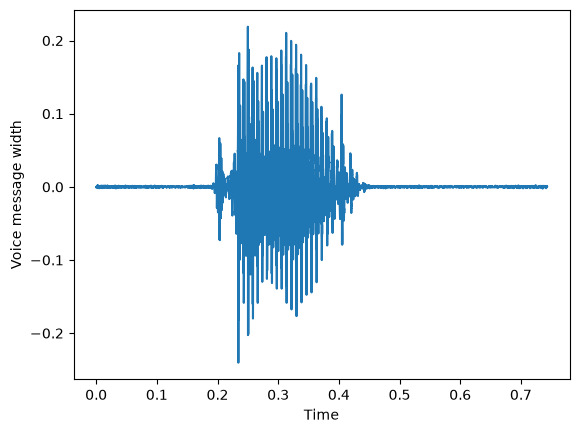

In [10]:
import matplotlib.pyplot as plt
import numpy as np
time = np.arange(len(wavs[0]))/16000
plt.plot( time, wavs[0])
plt.xlabel('Time')
plt.ylabel('Voice message width')
plt.show()

Το ακατέργαστο σήμα δεν είναι καλό χαρακτηριστικό για αναγνώριση για αυτό κόβουμε το σήμα σε μικρά παράθυρα 25ms με βήμα 10 ms άρα τα παράθυρα επικαλύπτονται. Σε κάθε παράθυρο έχουμε 400 αριθμούς οι οποιοί περιγράφουν την κυματομορφή. Από κάθε παράθυρο των 400 δειγμάτων εξάγουμε 13 MFCCs, οπότε κάθε παράθυρο γίνεται 1×13 διάνυσμα. Μαζί με τις πρώτες και τις δεύτερες παραγώγους 1x39. Κάθε εκφώνηση γίνεται πίνακας A x 39 όπου A ο αριθμός των παραθύρων και διαφέρει ανάλογα με τη διάρκεια κάθε ηχητικού μηνύματος. Για το wav[0]: 11891/16000 = 0.74 -> Α = 75

Για να κάνουμε extract τα MFCCs πρέπει να μετασχηματίσουμε το ακατέργαστο σήμα μέσω του FFT. Το librosa.feature.mfcc πραγματοποιεί τον παραπάνω μετασχηματισμό.

In [11]:
#Question 3
def extract_features(wavs, n_mfcc=13, Fs=16000):
    # Extract MFCCs for all wavs
    window = 25 * Fs // 1000
    step = 10 * Fs // 1000
    frames = [
        librosa.feature.mfcc(
            y=wav, sr=Fs, n_fft=window, hop_length=step, n_mfcc=n_mfcc
        ).T
        for wav in tqdm(wavs, desc="Extracting mfcc features...")
    ]

    print("Feature extraction completed with {} mfccs per frame".format(n_mfcc))
    delta1 = []
    delta2 = []
    for f in frames:
        delta1.append(librosa.feature.delta(f, order=1,axis=0))
        delta2.append(librosa.feature.delta(f, order=2,axis=0))

    return frames, delta1, delta2
frames,d1,d2 = extract_features(wavs)

Extracting mfcc features...: 100%|██████████| 133/133 [00:10<00:00, 12.42it/s]


Feature extraction completed with 13 mfccs per frame


To frames είναι μια λίστα με 133 στοιχεία όπου κάθε στοιχείο περιγράφει ένα ηχητικό μήνυμα. Κάθε στοιχείο είναι ένας πίνακας Ax13 όπου A είναι ο αριθμός των παραθύρων του αντίστοιχου ηχητικού. Κάθε γραμμή του πίνακα είναι τα MFCCs του αντίστοιχου παραθύρου

In [12]:
Matrix = frames[0] # 1st Voice message
Matrix.shape 

(75, 13)

Το πρώτο στοιχείο της λίστας frames αποτελεί τον πρώτο πίνακα ο οποίος έχει διάσταση 75x13, δηλαδή τα στοιχεία που περιγράφουν πρώτο ηχητικό μήνυμα

In [13]:
Matrix[0]

array([-731.6329   ,   92.468414 ,  -25.632584 ,   -7.151409 ,
         -7.168664 ,  -15.451456 ,  -24.163605 ,  -10.651527 ,
         21.99081  ,    4.2388315,  -26.828121 ,  -15.56683  ,
         -1.8172473], dtype=float32)

Η πρώτη γραμμή του πίνακα αποτελείται από τα MFCCs του πρώτου παραθύρου

In [14]:
# Question4
def extract_mfccs(n):
    index = [i for i,d in enumerate(digits) if d == n]
    frames2 = [frames[i]  for i in index]
    mfcc1 = []
    mfcc2 = []
    for i in range(len(frames2)):
        for j in range(len(frames2[i])):
            mfcc1.append(frames2[i][j][0])
            mfcc2.append(frames2[i][j][1])
    return mfcc1, mfcc2
mfcc1_4, mfcc2_4 = extract_mfccs('four')
mfcc1_7, mfcc2_7 = extract_mfccs('seven')

Αυτό που θέλουμε να κάνουμε πρακτικά είναι να πάρουμε τα πρώτα 2 MFCCs από όλα τα ηχητικά μηνύματα που εκφωνούν τον αριθμό 4 και 7. Δηλαδή πρέπει να πάρουμε όλους τους πίνακες (15 για το ψηφίο 4 και 15 για το ψηφίο 7) και σε κάθε γραμμή να πάρουμε το 1ο και το 2ο στοιχείο. Αυτον τον αλγόριθμο υλοποιεί η παραπάνω συνάρτηση.

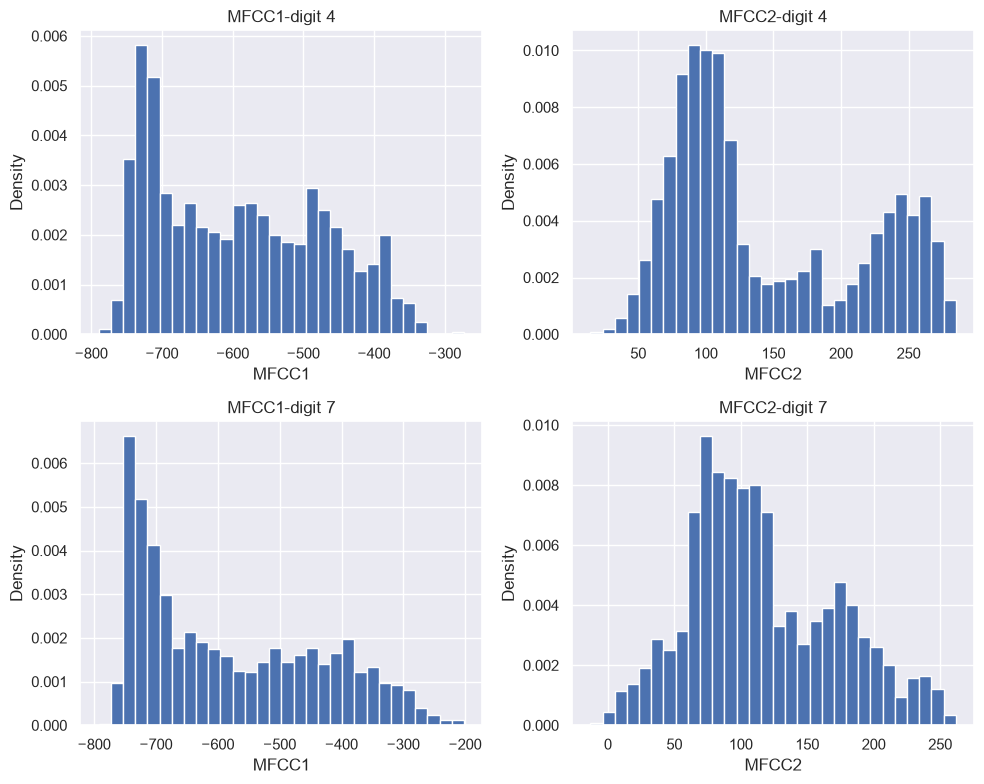

In [15]:
import seaborn as sns
sns.set_theme(style="darkgrid")
plt.figure(figsize=(10, 8))
#MFFC1-4
plt.subplot(2, 2, 1)
plt.hist(mfcc1_4, bins=30, density = True)
plt.title("MFCC1-digit 4")
plt.xlabel('MFCC1')
plt.ylabel('Density')
#MFCC2-4
plt.subplot(2, 2, 2)
plt.hist(mfcc2_4, bins=30, density = True)
plt.title("MFCC2-digit 4")
plt.xlabel('MFCC2')
plt.ylabel('Density')
#MFCC1-7
plt.subplot(2, 2, 3)
plt.hist(mfcc1_7, bins=30, density = True)
plt.title("MFCC1-digit 7")
plt.xlabel('MFCC1')
plt.ylabel('Density')
#MFCC2-7
plt.subplot(2, 2, 4)
plt.hist(mfcc2_7, bins=30, density = True)
plt.title("MFCC2-digit 7")
plt.xlabel('MFCC2')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

Δημιουργούμε ιστογράμματα για τον 1ο και τον 2ο MFCC των ψηφίων 4 και 7. Χρησιμοποιούμε density=True, ώστε ο άξονας y να δείχνει πυκνότητα και η σύγκριση να πραγματοποιείται ανεξάρτητα από το πλήθος των παραθύρων. Παρατηρείται σημαντική διασπορά μέσα σε κάθε ψηφίο. Αυτό οφείλεται στους διαφορετικούς εκφωνητές και στο γεγονός ότι ορισμένα παράθυρα είναι κενά (χωρίς ήχο) πριν και μετά την εκφώνηση. Το MFCC1 έχει παρόμοια κατανομή μεταξύ των δύο ψηφίων, επόμενως δεν τα διαχωρίζει. Στο MFCC2 παρατηρούνται ορισμένες διαφορές μεταξύ των κατανομών αλλά και πάλι στο μεγαλύτερο μέρος επικαλύπτονται.

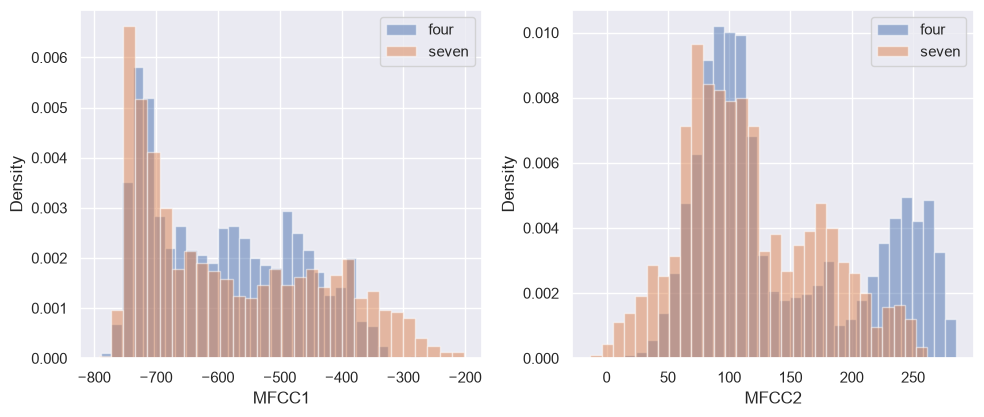

In [16]:
plt.figure(figsize=(10, 8))
plt.subplot(2,2,1)
plt.hist(mfcc1_4, bins=30, density=True, alpha=0.5, label='four')
plt.hist(mfcc1_7, bins=30, density=True, alpha=0.5, label='seven')
plt.xlabel('MFCC1')
plt.ylabel('Density')
plt.legend()
plt.subplot(2,2,2)
plt.hist(mfcc2_4, bins=30, density=True, alpha=0.5, label='four')
plt.hist(mfcc2_7, bins=30, density=True, alpha=0.5, label='seven')
plt.xlabel('MFCC2')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

Η διαδικασία δημιουργίας των MFCCs είναι η ακόλουθη :

Ακατέργαστος Ήχος -> Fourier Transformation -> Mel Filters -> Log Transformation -> DCT -> MFCCs

Τα MFSCs είναι η παραπάνω διαδικασία αλλά σταματάμε στο Log Transformation.

Η παρακάτω συνάρτηση δέχεται σαν όρισμα το ηχητικό μήνυμα σε μορφή .wav και υπολογίζει τα MFSCs. 

In [17]:
def mfsc(wav, n_mels = 13, Fs=16000):
    window = 25*Fs//1000
    step = 10*Fs//1000
    mel = librosa.feature.melspectrogram(y=wav, sr = Fs, n_fft = window, hop_length = step,n_mels = n_mels).T
    return np.log(1e-10 + mel)

In [18]:
def idx(n):
    return [i for i,d in enumerate(digits) if d == n][0:2]
mfsc4_a, mfsc4_b = [mfsc(wavs[i]) for i in idx('four')]
mfsc7_a, mfsc7_b = [mfsc(wavs[i]) for i in idx('seven')]
corr4a = np.corrcoef(mfsc4_a.T)
corr4b = np.corrcoef(mfsc4_b.T)
corr7a = np.corrcoef(mfsc7_a.T)
corr7b = np.corrcoef(mfsc7_b.T)

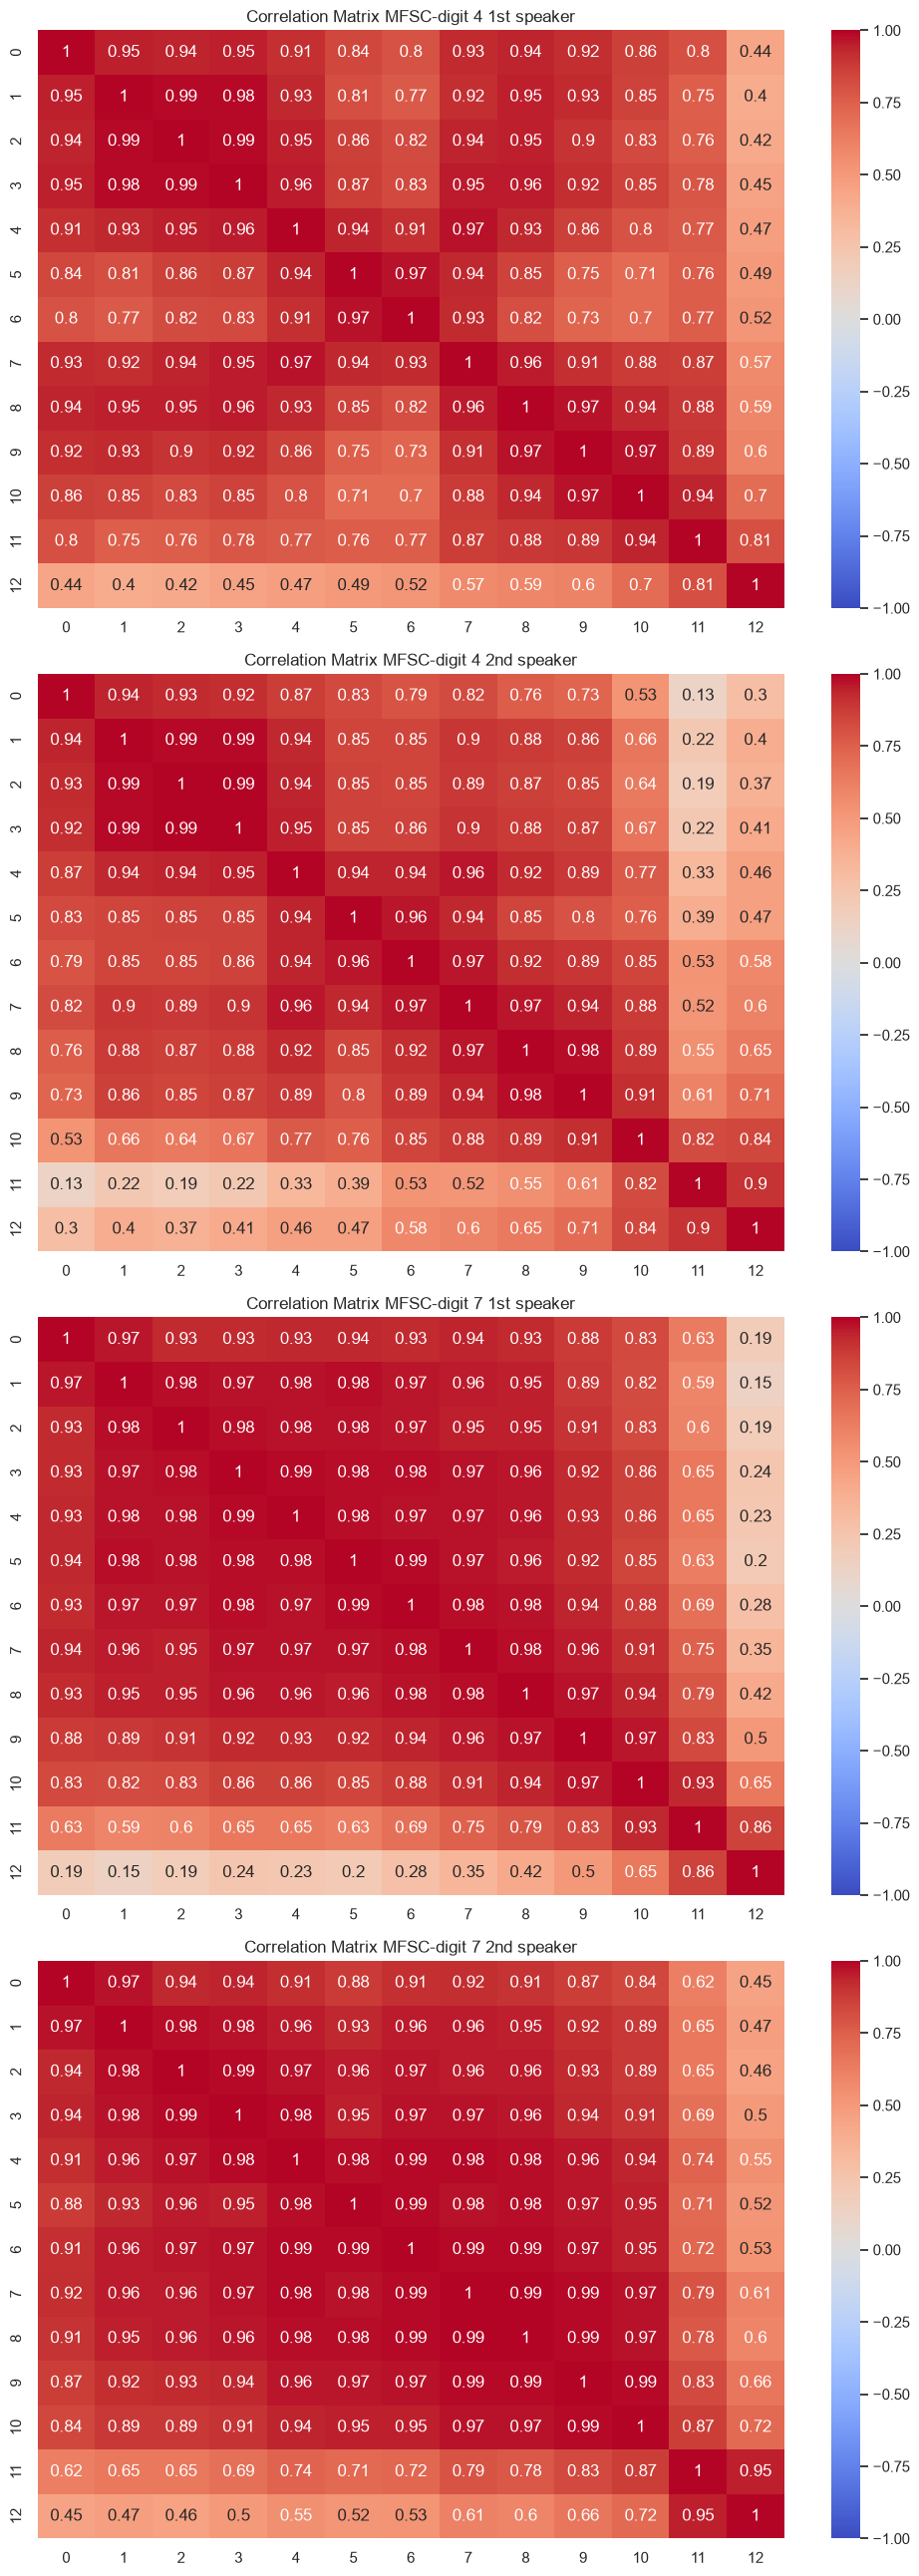

In [19]:
plt.figure(figsize = (10,26))
plt.subplot(4,1,1)
sns.heatmap(corr4a, annot= True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 4 1st speaker')

plt.subplot(4,1,2)
sns.heatmap(corr4b, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 4 2nd speaker')

plt.subplot(4,1,3)
sns.heatmap(corr7a, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 7 1st speaker')

plt.subplot(4,1,4)
sns.heatmap(corr7b, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFSC-digit 7 2nd speaker')

plt.tight_layout()
plt.show()

Παρατηρείται ότι τα MFSCs είναι έντονα θετικά συσχετισμένα με τη συσχέτιση να μειώνεται σημαντικά μόνο στο τελευταίο φίλτρο και στους δύο ομιλητές και στα δύο ψηφία.

In [20]:
corr4_mfcc1 = np.corrcoef(frames[idx('four')[0]].T)
corr4_mfcc2 = np.corrcoef(frames[idx('four')[1]].T)
corr7_mfcc1 = np.corrcoef(frames[idx('seven')[0]].T)
corr7_mfcc2 = np.corrcoef(frames[idx('seven')[1]].T)

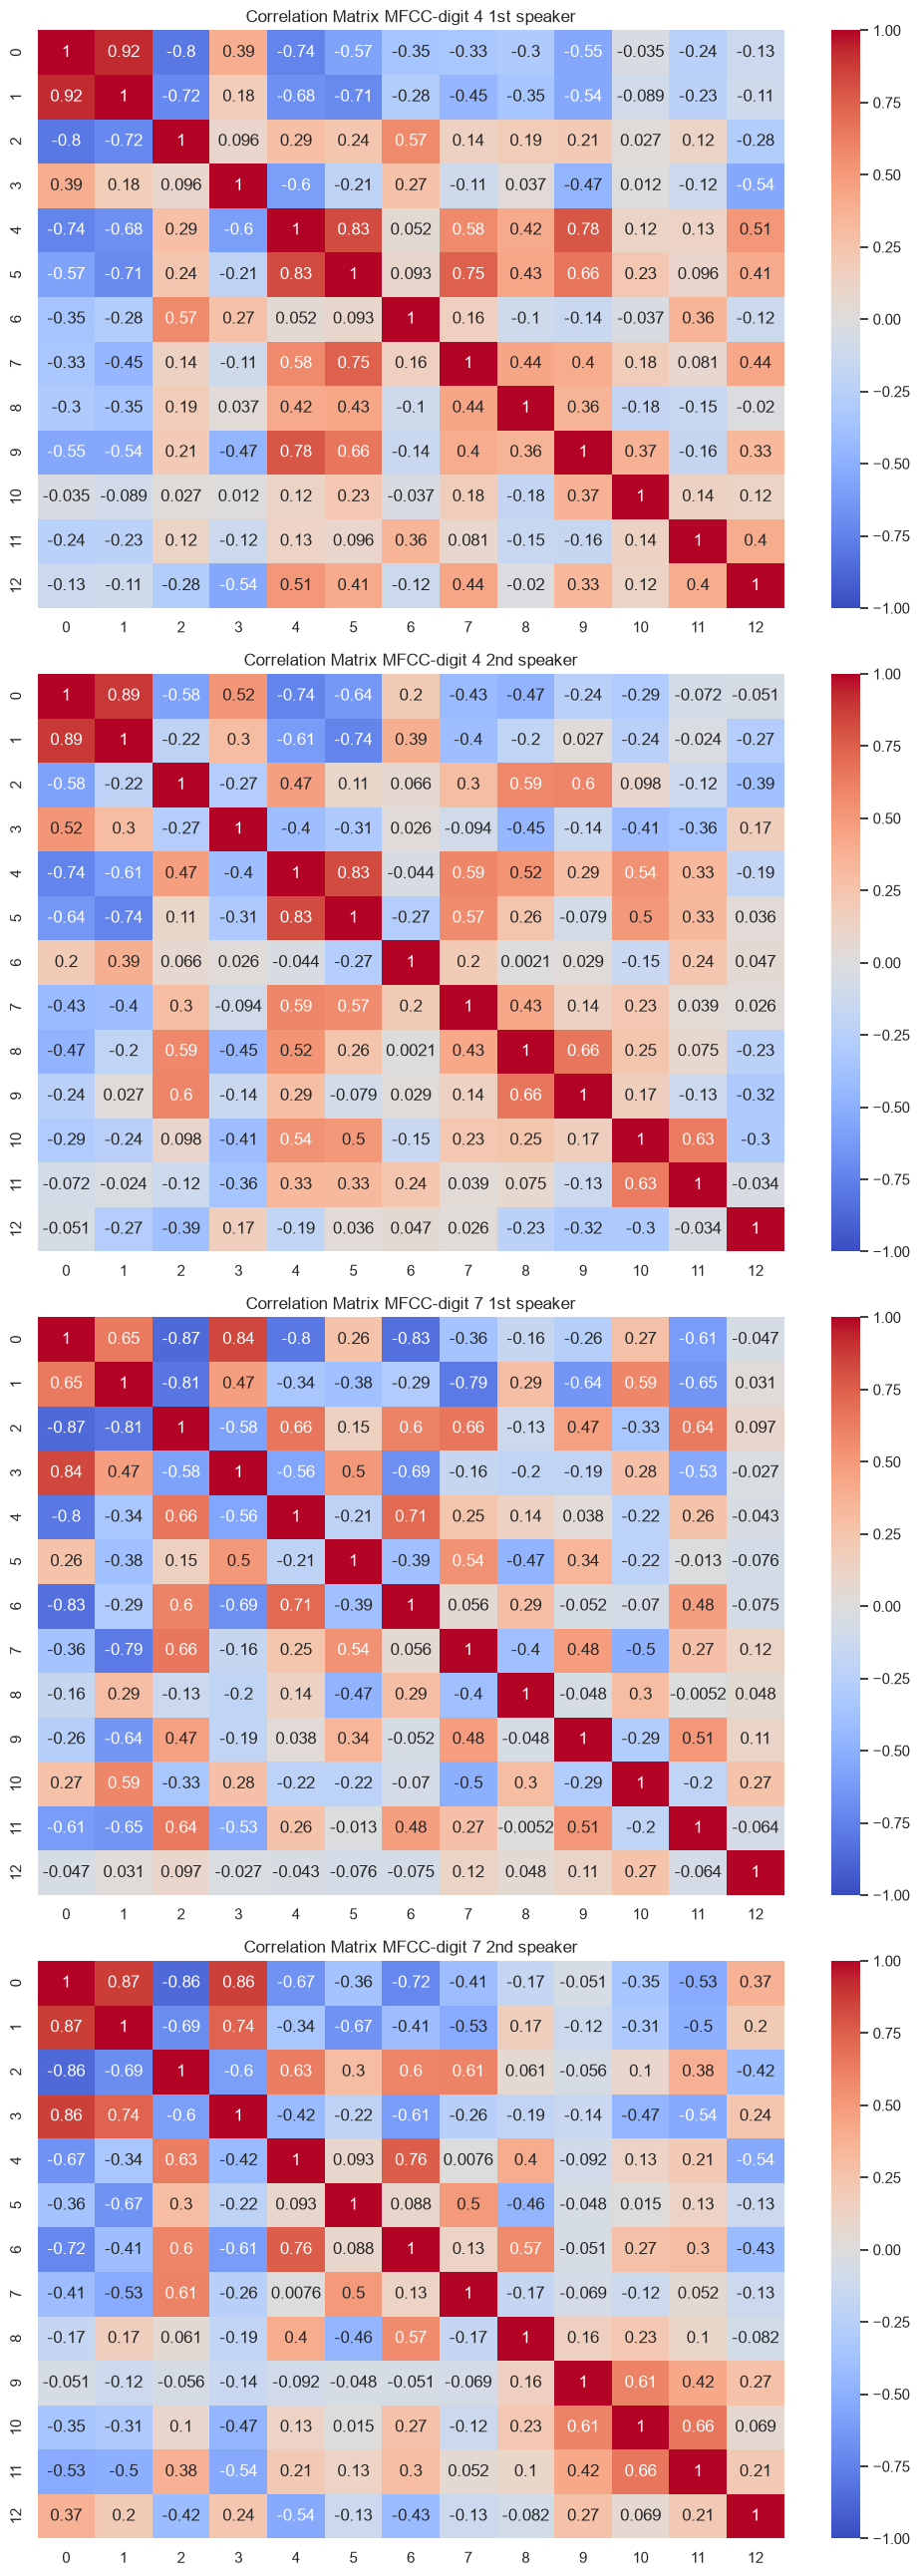

In [21]:
plt.figure(figsize = (10,26))
plt.subplot(4,1,1)
sns.heatmap(corr4_mfcc1, annot= True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 4 1st speaker')

plt.subplot(4,1,2)
sns.heatmap(corr4_mfcc2, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 4 2nd speaker')

plt.subplot(4,1,3)
sns.heatmap(corr7_mfcc1, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 7 1st speaker')

plt.subplot(4,1,4)
sns.heatmap(corr7_mfcc2, annot = True,vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix MFCC-digit 7 2nd speaker')

plt.tight_layout()
plt.show()

Από τα correlation heatmaps των MFCCs παρατηρείται ότι σε αντίθεση με τα MFSCs όπου σχεδόν όλα τα ζεύγη έχουν υψηλή συσχέτιση οι συσχετίσεις στα MFCCs είναι πολύ μικρότερες κατά απόλυτη τιμή και με διαφορετικά πρόσημα. Έτσι αντιλαμβανόμαστε ότι το DCT (Discrete Cosine Transform - Διακριτικός Μετασχηματισμός Συνημιτόνου) αποσυσχετίζει σε μεγάλο βαθμό τα χαρακτηριστικά.

In [22]:
# Question 5
vector=[]
for i in range(len(frames)):
    vector.append(np.hstack([frames[i], d1[i], d2[i]]))

Τα frames,d1,d2 ήταν λίστες με 133 στοιχεία τα οποία ήταν πίνακες μεγέθους Αx13. Ο παραπάνω κώδικας ενώνει τους πίνακες προσθέτωντας τοποθετώντας τους πίνακες τον έναν δίπλα στον άλλον άρα πλέον έχουμε ένα διάνυσμα (λίστα) με όνομα vector το οποίο αποτελείται από 133 (στοιχεία) πίνακες μεγέθους Ax39 όπου A ο αριθμός των παραθύρων κάθε ηχητικού μηνύματος.

In [23]:
mean=[]
std = []
for i in range(len(vector)):
    mean.append(np.mean(vector[i], axis=0))
    std.append(np.std(vector[i], axis = 0))
X = np.hstack([mean,std])

Στη συνέχεια δημιουργούμε 2 λίστες: μια λίστα με όνομα mean που περιέχει 133 πίνακες 39x1 δηλαδή ένα διάνυσμα με 39 στοιχεία τα οποία αποτελούν τις μέσες τιμές των MFCCs,deltas και deltas-deltas κάθε φωνητικού μηνύματος. Και μία λίστα με όνομα std που περιέχει 133 διανύσματα με 39 τιμές οι οποίες είναι οι τυπικές αποκλίσεις. Τέλος δημιουργούμε έναν πίνακα διάστασης 133x78 όπου κάθε γραμμή αποτελεί ένα ηχητικό μήνυμα και οι 78 στήλες είναι οι μέσες τιμές και οι τυπικές αποκλίσεις κάθε χαρακτηριστικού.

In [24]:
X.shape

(133, 78)

**Με απλά λόγια**

Συμπερασματικά,δημιουργούμε μια λιστα με 133 πίνακες Ax39 (vector). Στη συνέχεια παίρνουμε μέσες τιμές και τυπικές αποκλίσεις κάθε στηλης(mean,std). Και δημιουργούμε εναν πίνακα (X) με 133 γραμμές(μία για καθε φωνητικό). Κάθε γραμμή αποτελείται από 78 στοιχεία, όπου τα 39 πρωτα στοιχεια να ειναι οι μεσες τιμες καθε χαρακτηριστικου και τα υπολοιπα 39 να ειναι οι τυπικες αποκλισεις καθε χαρακτηριστικου.

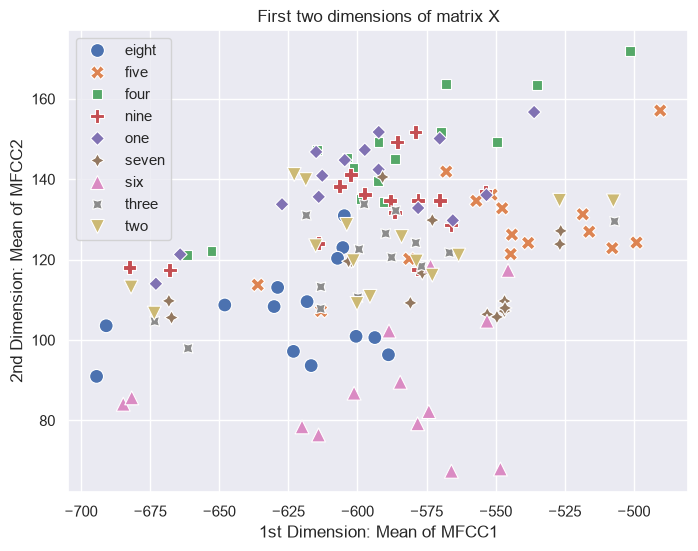

In [25]:
dim1 = X[:,0]
dim2 = X[:,1]

plt.figure(figsize=(8, 6))
sns.scatterplot(x=dim1,y=dim2,s=100, hue=digits, style = digits)
plt.xlabel('1st Dimension: Mean of MFCC1')
plt.ylabel('2nd Dimension: Mean of MFCC2')
plt.title('First two dimensions of matrix X')
plt.show()

Δημιουργούμε scatterplot μεταξύ των δύο πρώτων διαστάσεων (στηλών) του πίνακα Χ. Για κάθε ψηφίο χρησιμοποιούμε διαφορετικό σύμβολο και χρώμα απεικόνισης.

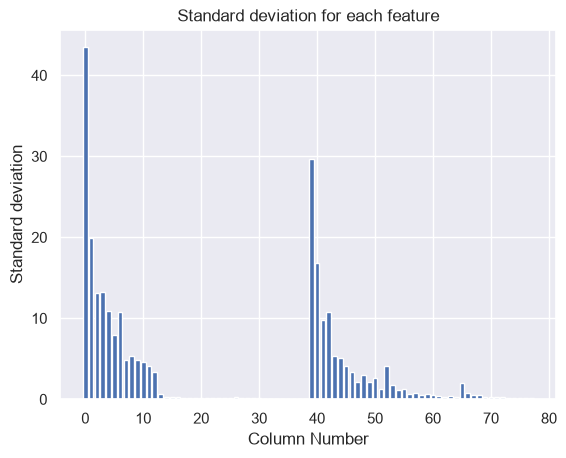

In [26]:
plt.bar(range(78), np.std(X, axis=0))
plt.xlabel('Column Number')
plt.ylabel('Standard deviation')
plt.title('Standard deviation for each feature')
plt.show()

In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
pca.fit(X_scaled)
X_pca = pca.transform(X_scaled)
var_expl = pca.explained_variance_ratio_
print('Dimensions before:', X.shape)
print('Dimensions after pca:',X_pca.shape)
print('Variance explained:',var_expl)
print('Total variance explained:',sum(var_expl))

Dimensions before: (133, 78)
Dimensions after pca: (133, 2)
Variance explained: [0.11208327 0.08855751]
Total variance explained: 0.20064078


Κανονικοποιούμε τα δεδομένα διότι οι τιμές του πίνακα Χ διαφέρουν αρκέτα με αποτέλεσμα οι τιμές να βρίσκονται σε διαφορετική κλίμακα, γεγονός που καθιστά το scaling απαραίτητο.Πραγματοποιήσαμε Principal Component Analysis με σκοπό τη μείωση των διαστάσεων από 78 σε 2. Η διακύμανση που εξηγείται από τις 2 κύριες συνιστώσες είναι περίπου 20% (11.2% από την πρώτη και 8.9% από την δεύτερη). Επόμενως, η μείωση των διαστάσεων δεν είναι επιτυχημένη ως προς την διατήρηση της πληροφορίας διότι 'χάνεται' το 80% της διασποράς.

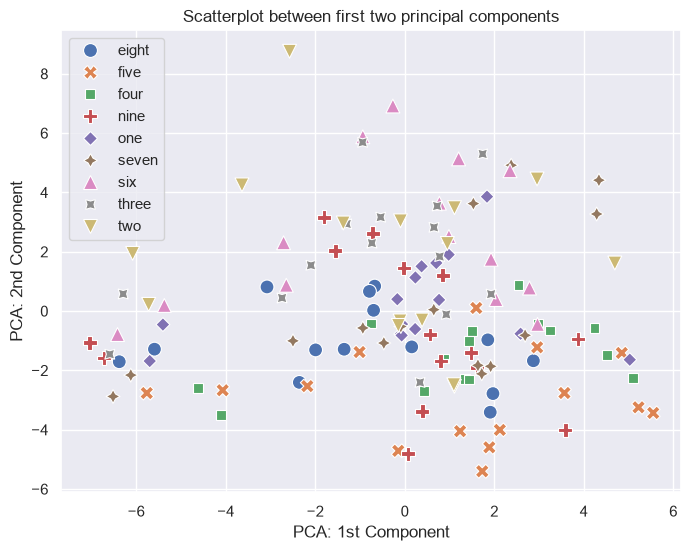

In [28]:
dim1_pca = X_pca[:,0]
dim2_pca = X_pca[:,1]

plt.figure(figsize=(8, 6))
sns.scatterplot(x=dim1_pca,y=dim2_pca,s=100, hue=digits, style = digits)
plt.xlabel('PCA: 1st Component')
plt.ylabel('PCA: 2nd Component')
plt.title('Scatterplot between first two principal components')
plt.show()

In [29]:
# Pca with 3 principal components
pca2 = PCA(n_components = 3)
pca2.fit(X_scaled)
X_pca2 = pca2.transform(X_scaled)
var_expl2 = pca2.explained_variance_ratio_
print('Dimensions before:', X.shape)
print('Dimensions after pca:',X_pca2.shape)
print('Variance explained:',var_expl2)
print('Total variance explained:',sum(var_expl2))

Dimensions before: (133, 78)
Dimensions after pca: (133, 3)
Variance explained: [0.11208327 0.08855751 0.06606889]
Total variance explained: 0.2667097


Στην περίπτωση του PCA με αριθμό κύριων συνιστώσων ίσο με 3 δεν αλλάζει κάτι ως προς την εξήγηση της διακύμανσης των κύριων συνιστωσών. Και σε αυτή την περίπτωση το ποσοστό της διακύμανσης που εξηγείται είναι χαμηλό περίπου 26.7% (11.2% από τη 1η, 8.8% από τη 2η και 6.6% από την τρίτη). Άρα και σε αυτήν την περίπτωση η μείωση των διαστάσεων δεν είναι επιτυχημένη.

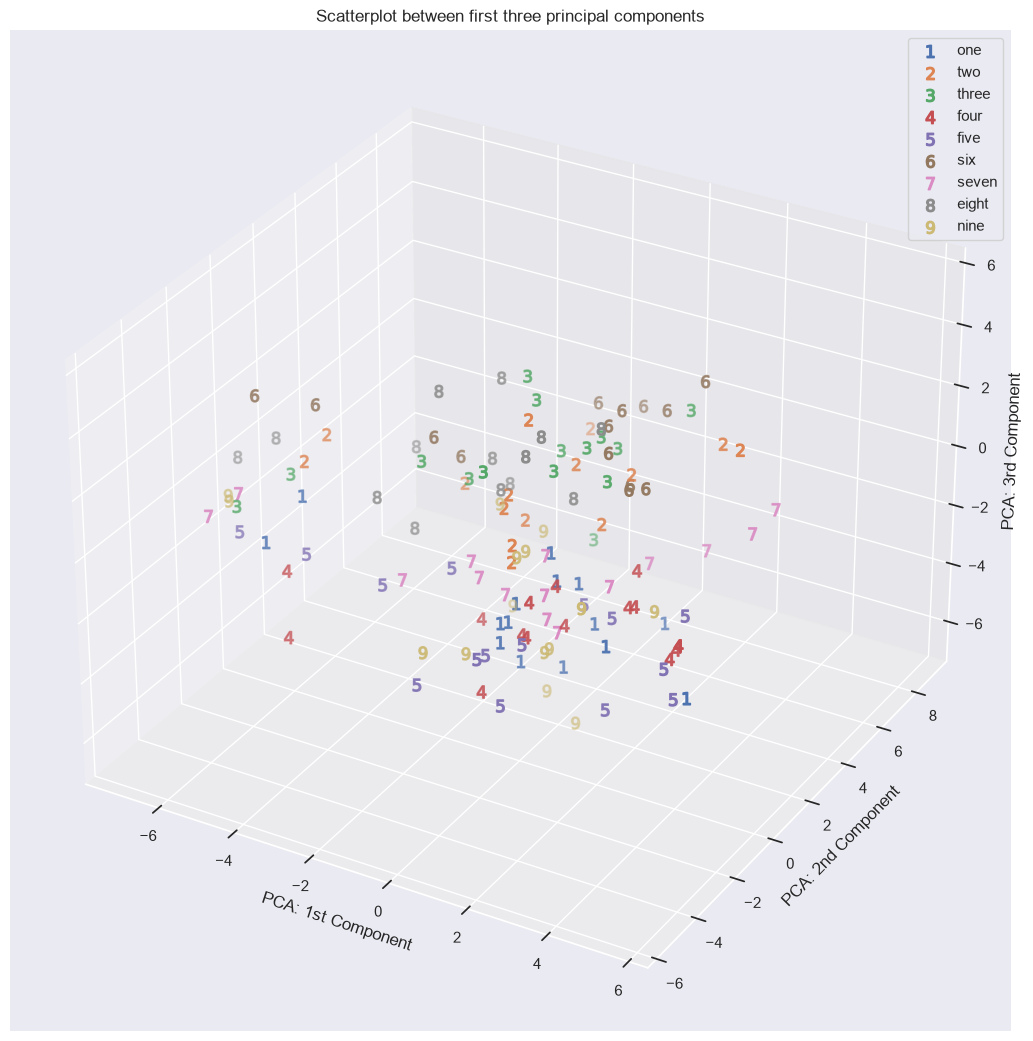

In [30]:
def mark(x):
    return f'${x}$'
markers = [mark(x) for x in range(1,10)]
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(projection='3d')
num = {'one':1,'two':2,'three':3,'four':4,'five':5,'six':6,'seven':7,'eight':8,'nine':9}

for d in num.keys():
    mask = (np.array(digits) == d)
    ax.scatter(X_pca2[mask, 0], X_pca2[mask, 1], X_pca2[mask, 2],
               marker=mark(num[d]), s=80, label=d, alpha = 1)
ax.set_xlabel('PCA: 1st Component')
ax.set_ylabel('PCA: 2nd Component')
ax.set_zlabel('PCA: 3rd Component')
ax.set_title('Scatterplot between first three principal components')
ax.legend()
plt.show()

In [72]:
# Question 7
from sklearn.model_selection import train_test_split
y = np.array(digits)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 42, stratify=y)
train_scaler= scaler.fit(X_train)
X_train_scaled = train_scaler.transform(X_train)
X_test_scaled = train_scaler.transform(X_test)

In [73]:
def euclidean_distance(s, m):
    return np.sqrt(np.sum((s-m)**2))

def euclidean_distance_classifier(X, X_mean):
    predictions = []
    for s in X:
        d = [euclidean_distance(s,m) for m in X_mean]
        predictions.append(np.argmin(d))
    return np.array(predictions)

from sklearn.base import BaseEstimator, ClassifierMixin
class EuclideanDistanceClassifier(BaseEstimator, ClassifierMixin):
    """Classify samples based on the distance from the mean feature value"""

    def __init__(self):
        self.X_mean_ = None


    def fit(self, X, y):
        """
        This should fit classifier. All the "work" should be done here.

        Calculates self.X_mean_ based on the mean
        feature values in X for each class.

        self.X_mean_ becomes a numpy.ndarray of shape
        (n_classes, n_features)

        fit always returns self.
        """
        self.classes_ = np.unique(y)
        self.X_mean_ = np.array([X[y==c].mean(axis=0) for c in self.classes_])
        return self


    def predict(self, X):
        index = euclidean_distance_classifier(X,self.X_mean_)
        return self.classes_[index]

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

In [74]:
def classify(classifier, X_train, y_train, X_test, y_test):
    classifier.fit(X_train, y_train)
    print(f'{classifier}-Accuracy (Train):',round(classifier.score(X_train, y_train),2))
    print(f'{classifier}-Accuracy (Test):', round(classifier.score(X_test, y_test),2))
    print('')
    return

from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
classifiers = [EuclideanDistanceClassifier(),GaussianNB(),MLPClassifier(random_state=42, max_iter = 240),SVC(),RandomForestClassifier(random_state=42)]
for c in classifiers:
    classify(c, X_train_scaled, y_train, X_test_scaled, y_test)

EuclideanDistanceClassifier()-Accuracy (Train): 0.92
EuclideanDistanceClassifier()-Accuracy (Test): 0.62

GaussianNB()-Accuracy (Train): 0.96
GaussianNB()-Accuracy (Test): 0.65

MLPClassifier(max_iter=240, random_state=42)-Accuracy (Train): 1.0
MLPClassifier(max_iter=240, random_state=42)-Accuracy (Test): 0.62

SVC()-Accuracy (Train): 1.0
SVC()-Accuracy (Test): 0.62

RandomForestClassifier(random_state=42)-Accuracy (Train): 1.0
RandomForestClassifier(random_state=42)-Accuracy (Test): 0.65



In [108]:
# Bonus
def new_features(wavs, Fs=16000):
    window = 25*Fs//1000
    step  = 10*Fs//1000
    X_zcr = []
    X_rms = []
    X_sc = []
    X_sb = []
    X_sr = []
    X_sf = []
    for w in wavs:
        zcr = librosa.feature.zero_crossing_rate(w, frame_length=window, hop_length=step)[0]
        rms = librosa.feature.rms(y=w, frame_length=window, hop_length=step)[0]
        sc = librosa.feature.spectral_centroid(y=w, sr=Fs, n_fft=window, hop_length=step)[0]
        sb = librosa.feature.spectral_bandwidth(y=w, sr=Fs, n_fft=window, hop_length=step)[0]
        ro = librosa.feature.spectral_rolloff(y=w, sr=Fs, n_fft=window, hop_length=step)[0]
        sf = librosa.feature.spectral_flatness(y=w, n_fft=window, hop_length=step)[0]

        X_zcr.append([zcr.mean(), zcr.std()])
        X_rms.append([rms.mean(), rms.std()])
        X_sc.append([sc.mean(), sc.std()])
        X_sb.append([sb.mean(), sb.std()])
        X_sr.append([ro.mean(), ro.std()])
        X_sf.append([sf.mean(), sf.std()])
    return np.hstack([X_zcr, X_rms, X_sc, X_sb, X_sr, X_sf])

X_bonus = np.hstack([X, new_features(wavs)])
X_bonus.shape

(133, 90)

Το **zero crossing rate** είναι το ποσοστό των διαδοχικών δειγμάτων ενός παραθύρου στα οποία το σήμα αλλάζει πρόσημο

Το **root mean square** είναι η τετραγωνική ρίζα της μέσης τιμής των τετραγώνων των δειγμάτων ενός παραθύρου και εκφράζει την ενέργεια (ένταση) του σήματος

Το **spectral centroid** είναι το κέντρο βάρους του φάσματος κάθε παραθύρου, δηλαδή ο μέσος όρος των συχνοτήτων σταθμισμένος με το πλάτος τους. Δείχνει σε ποια περιοχή συχνοτήτων συγκεντρώνεται η ενέργεια

Το **spectral bandwidth** είναι η σταθμισμένη τυπική απόκλιση των συχνοτήτων του φάσματος γύρω από το spectral centroid και δείχνει πόσο απλωμένη είναι η ενέργεια στις συχνότητες

Το **spectral rolloff** είναι η συχνότητα κάτω από την οποία βρίσκεται το 85% της συνολικής ενέργειας του φάσματος κάθε παραθύρου (Το librosa χρησιμοποιεί rolloff_percent = 0.85)

Το **spectral flatness** δείχνει πόσο ομοιόμορφα είναι κατανεμημένη η ενέργεια στις συχνότητες. Παίρνει τιμές κοντά στο 1 όταν ο ήχος μοιάζει με θόρυβο και κοντά στο 0 όταν η ενέργεια συγκεντρώνεται σε λίγες συχνότητες (φωνήεντα).


In [105]:
X_trainb, X_testb, y_trainb, y_testb= train_test_split(X_bonus, y,test_size = 0.3, random_state = 42, stratify = y)
trainb_scaler = scaler.fit(X_trainb)
X_trainb_scaled = trainb_scaler.transform(X_trainb)
X_testb_scaled = trainb_scaler.transform(X_testb)

In [109]:
classifiers = [EuclideanDistanceClassifier(),GaussianNB(),MLPClassifier(random_state=42, max_iter = 300),SVC(),RandomForestClassifier(random_state=42)]
for c in classifiers:
    classify(c, X_trainb_scaled, y_trainb, X_testb_scaled, y_testb)

EuclideanDistanceClassifier()-Accuracy (Train): 0.92
EuclideanDistanceClassifier()-Accuracy (Test): 0.6

GaussianNB()-Accuracy (Train): 0.94
GaussianNB()-Accuracy (Test): 0.68

MLPClassifier(max_iter=300, random_state=42)-Accuracy (Train): 1.0
MLPClassifier(max_iter=300, random_state=42)-Accuracy (Test): 0.7

SVC()-Accuracy (Train): 1.0
SVC()-Accuracy (Test): 0.68

RandomForestClassifier(random_state=42)-Accuracy (Train): 1.0
RandomForestClassifier(random_state=42)-Accuracy (Test): 0.7



In [110]:
# Question 8